In [3]:
from anemone.forwards import *
from anemone.experiment import *
import matplotlib.pyplot as plt
import numpy as np

In [4]:
from libaarhusxyz import GEX
gex = GEX("TX11_3x3_1_turn.gex")
HMwv = Waveform(gex.General['WaveformHMPoint'][:, 0], gex.General['WaveformHMPoint'][:, 1])

header [General] parsed
header [Channel1] parsed
header [Channel2] parsed


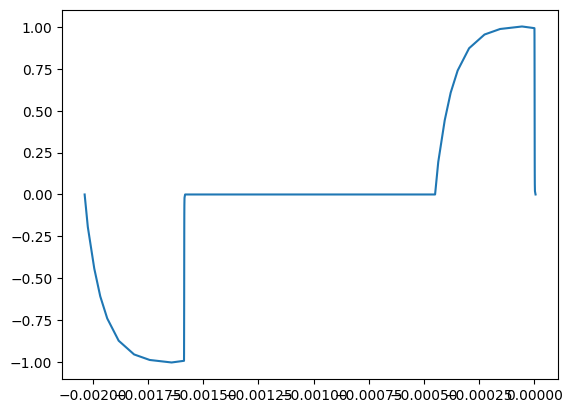

In [5]:
plt.figure()
plt.plot(HMwv.time, HMwv.amplitude, label='HM Point')


In [6]:
# tx = Loop.circle(50, n=16)
tx = Loop.square(0.25)
# tx.x = tx.x[:2]
# tx.y = tx.y[:2]
# tx.z = tx.z[:2]
rx = Receiver()
t = torch.logspace(-10, 0, 51)
wv = Waveform(HMwv.time[len(HMwv.time)//2:], HMwv.amplitude[len(HMwv.amplitude)//2:])
wv = HMwv

# wv.time[-1] = 1e-6
# wv.time[0] = -2e-3
# wv.calc_d2wdt2()

fwr = ForwardLaplace7(tx, rx, t, waveform=wv, tolerance=1e-6)
fwr0 = Forward(tx, rx, t, waveform=wv)

rho = torch.ones(2)*10.
thk = torch.tensor([30])

dbdt = fwr(rho.clone(), thk.clone())
# dbdt0 = fwr0(rho, thk)

shape of lambda:  torch.Size([301])


c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [7]:
#%%timeit
fwr = OnTimeForward(tx, rx, t, wv)
dbdt_on = fwr(rho.clone(), thk.clone())
# fwr.t2t[:,1]=0.

shape of lambda:  torch.Size([301])
shape of lambda:  torch.Size([301])


In [8]:
import numpy as np
from scipy.special import erf
def hz_halfspace_center_circle_loop_time(times, rho, r, I=1.):
    sigma = 1./rho
    theta = np.sqrt(0.25*4*np.pi*1e-7*sigma / times)
    theta_r = theta*r
    hz = 3*np.exp(-theta_r**2)/(r*theta*np.sqrt(np.pi)) + (1 - 3 / (2*theta_r**2))*erf(theta_r)
    hz *= I/(2*r)
    return hz

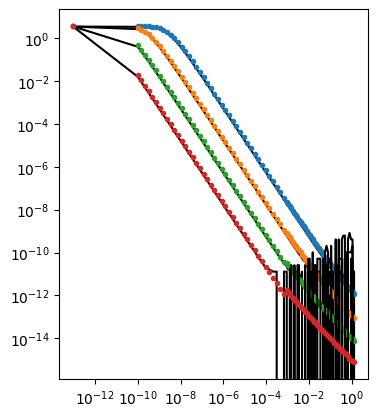

In [9]:
import anemone

# from anemone.physics import hz_halfspace_center_circle_loop_time
fig,ax = plt.subplots()
decimate = slice(None, None)
for i,rho_halspace in enumerate([1, 10, 100, 1000]):
    # rho[i] = rho_halspace
    # thk[i] = 30
    _t = np.concatenate([np.ones(1)*1e-13, fwr.t_in.numpy()])

    bstep_analytic = hz_halfspace_center_circle_loop_time(_t, rho_halspace, np.sqrt(tx.area/np.pi))
    ax.loglog(_t, bstep_analytic, 'k-', label='analytic')
    
    rho = torch.ones(2)*rho_halspace

    dbdt_on = fwr(rho, thk)




    ax.loglog(_t[decimate],  fwr.bstep[decimate]/anemone.constants.mu0, f'C{i}.')
    ax.loglog(_t[decimate], -fwr.bstep[decimate]/anemone.constants.mu0, f'C{i}x')

    # dbdt_on = fwr(rho, thk)
    # ax.loglog(_t,  fwr.bstep/anemone.constants.mu0, '.-')
    # ax.loglog(_t, -fwr.bstep/anemone.constants.mu0, 'x-')

ax.set_aspect(1)
    # plt.xlim(1e-6, 1e-3)

In [8]:
%%timeit
dbdt_on = fwr(rho, thk)

81.4 ms ± 12.6 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [9]:
from anemone.physics import hzdt_halfspace_center_circle_loop

In [10]:
rho = torch.ones(2)*100.


In [11]:
dbdt_half = hzdt_halfspace_center_circle_loop(t, rho[0], torch.sqrt(torch.tensor([tx.area/np.pi], dtype=torch.double)))*anemone.constants.mu0

In [1]:
fwr = OnTimeForward(tx, rx, t, wv)

plt.figure(figsize=(10, 6))

for i in range(2):
    dbdt_on = fwr(rho, thk)
    fwr.t2t[:,:2]=0.

    plt.loglog(fwr.times,  dbdt_on, f'C{i}')
    plt.loglog(fwr.times, -dbdt_on, f'C{i}--')
plt.loglog(t, dbdt_half, 'k--', label='Halfspace')

NameError: name 'OnTimeForward' is not defined

C:\Users\au646858\AppData\Local\Temp\ipykernel_27288\3904792506.py:5: RuntimeWarning: divide by zero encountered in log10
  pcm=axs[1].pcolor(fwr.t_in.log10()[1:], fwr.times.log10(), np.log10(np.abs(fwr.t2t[:, 2:])))
C:\Users\au646858\AppData\Local\Temp\ipykernel_27288\3904792506.py:6: MatplotlibDeprecationWarning: Getting the array from a PolyQuadMesh will return the full array in the future (uncompressed). To get this behavior now set the PolyQuadMesh with a 2D array .set_array(data2d).
  plt.colorbar(pcm, ax=axs[1])


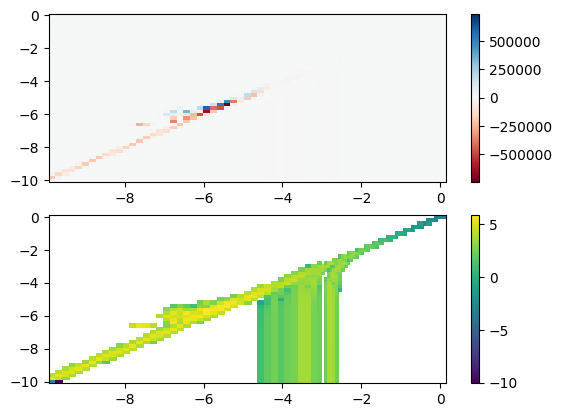

In [13]:
vlim = np.nanmax(np.abs(fwr.t2t[:,2:]))
fig,axs = plt.subplots(2,1)
pcm=axs[0].pcolor(fwr.t_in.log10()[1:], fwr.times.log10(), fwr.t2t[:, 2:], vmin=-vlim, vmax=vlim, cmap='RdBu')
plt.colorbar(pcm, ax=axs[0])
pcm=axs[1].pcolor(fwr.t_in.log10()[1:], fwr.times.log10(), np.log10(np.abs(fwr.t2t[:, 2:])))
plt.colorbar(pcm, ax=axs[1])

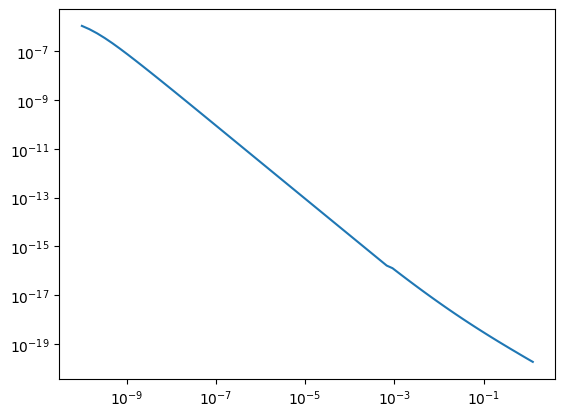

In [14]:
plt.figure()
plt.loglog(fwr.t_in, fwr.bstep[1:])

NameError: name 'dbdt0' is not defined

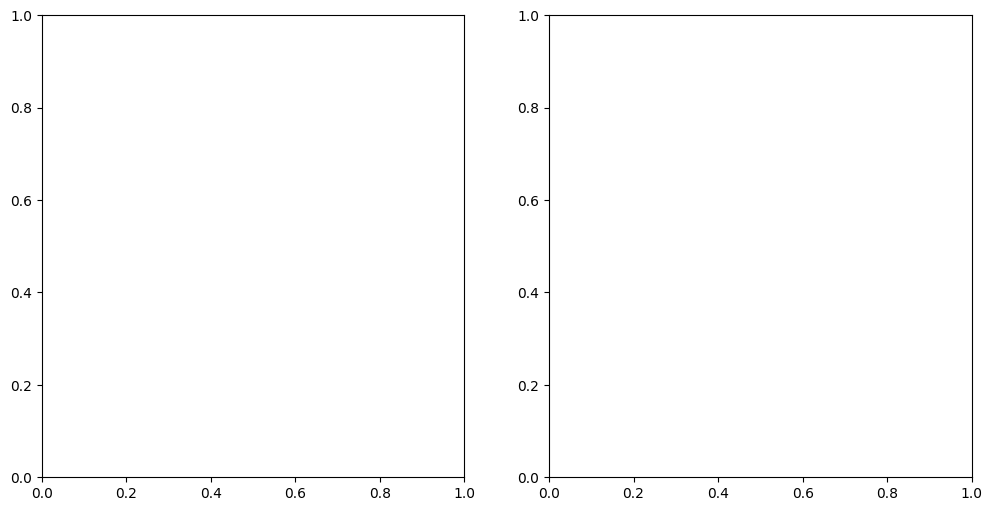

In [15]:
import matplotlib.pyplot as plt
import numpy as np

fig,axs = plt.subplots(1, 2, figsize=(12, 6), sharex=True)
axs[0].loglog(fwr0.times, dbdt0, 'C0-')
axs[0].loglog(fwr.times, dbdt, 'k.')
axs[0].loglog(fwr0.times, -dbdt0, 'C0--')
axs[0].loglog(fwr.times,  -dbdt, 'kx')
axs[1].semilogx(fwr0.times, 100*np.abs(dbdt-dbdt0)/np.abs(dbdt0))
# axs[1].set_ylim(0, 50)

In [ ]:
vlim = np.nanmax(np.abs(fwr.t2t))
pcm = plt.pcolor(torch.log10(fwr.t_eval), torch.log10(fwr.times), fwr.t2t, cmap='seismic', vmin=-vlim, vmax=vlim)
plt.colorbar(pcm)

AttributeError: 'OnTimeForward' object has no attribute 't_eval'

In [1]:
import biotsavart
import anemone

Bsteady_tx = biotsavart.Loop.square(1)
Bsteady_rx = biotsavart.ObsPoint()
Bsteady    = biotsavart.calc_bfield(Bsteady_tx.xyz, Bsteady_rx.xyz) / anemone.constants.mu0

In [2]:
from anemone.physics import hzdt_halfspace_center_circle_loop
import anemone

#rho = torch.tensor([20, 30, 40])
thk = torch.tensor([30,30])

fig,axs = plt.subplots(1,3, figsize=(12, 6))

for i,rho_halfspace in enumerate(torch.logspace(-1, 3, 5)):
    dbdt  = fwr(rho_halfspace * torch.ones_like(rho), thk)
    dbdt0 = fwr0(rho_halfspace * torch.ones_like(rho), thk)

    axs[0].loglog(fwr.t_eval, fwr.bstep, label=f'{rho_halfspace:.1f} ohm m')
    axs[0].loglog(fwr.times, fwr0.bstep, f'C{i}.', label=f'{rho_halfspace:.1f} ohm m')
    

    dbdt_analytic = hzdt_halfspace_center_circle_loop(fwr.times, rho_halfspace, 20.)*anemone.constants.mu0

    axs[1].loglog(fwr.times,  dbdt0,  f'C{i}-', label=f'{rho_halfspace:.1f} ohm m')
    axs[1].loglog(fwr.times, -dbdt0, f'C{i}--')
    axs[1].loglog(fwr.times, dbdt_analytic, f'C{i}.')
    axs[1].loglog(fwr.times, -dbdt_analytic, f'C{i}x')

    axs[-1].loglog(fwr.times,  dbdt,  f'C{i}-', label=f'{rho_halfspace:.1f} ohm m')
    axs[-1].loglog(fwr.times, -dbdt, f'C{i}--')

    axs[-1].loglog(fwr.times,  dbdt0,  f'C{i}.', label=f'{rho_halfspace:.1f} ohm m')
    axs[-1].loglog(fwr.times, -dbdt0, f'C{i}x')

axs[0].loglog(fwr.times, torch.ones_like(fwr.times) * Bsteady[2], 'k--', label='steady state')

NameError: name 'torch' is not defined

In [ ]:
class OnTimeForward():
    hankel = None
    laplace = None
    t2t = None

    def __init__(self, radius, times, waveform, tolerance=None, t_smp_per_decade=6):
        self.radius = radius
        self.receiver = Receiver()
        self.times = times
        self.tmin = times.min().to(torch.double)/10
        self.tmax = times.max().to(torch.double)*10
        self.device = times[0].device
        from biotsavart import Loop, ObsPoint, calc_bfield
        _loop = Loop.circle(radius)
        _obs = ObsPoint(self.receiver.x.numpy(), self.receiver.y.numpy(), self.receiver.z.numpy())
        self.pfield = torch.from_numpy(calc_bfield(_loop.xyz, _obs.xyz)[..., 2]).reshape([1])# / c.mu0

        self.waveform = waveform
        self.tmin += -self.waveform.time.max()
        if self.tmin < 0:
            self.tmin = torch.tensor([1e-11])
        self.tmax += -self.waveform.time.min()
        waveform.time = waveform.time.to(self.device)
        waveform.amplitude = waveform.amplitude.to(self.device)
        waveform.d2wdt2 = waveform.d2wdt2.to(self.device)        
        self.t_smp_per_decade = t_smp_per_decade
        self.t_eval = torch.logspace(self.tmin.log10().item(), self.tmax.log10().item(), int(t_smp_per_decade*torch.log10(self.tmax/self.tmin)), dtype=torch.double, device=self.device)
        self.t2t = waveform_matrix_with_primary(self.t_eval, self.times, self.waveform)
        self.tolerance=tolerance
        if self.device is not None:
            for attr_name in self.__dict__:
                attr_value = getattr(self, attr_name)
                if torch.is_tensor(attr_value):
                    setattr(self, attr_name, attr_value.to(self.device))
        
    def forward2(self):
        
        bstep = hz_halfspace_center_circle_loop_time(self.t_eval, self.rho, self.radius)* anemone.constants.mu0
        self.bstep = torch.concat([-self.pfield, bstep], dim=0)
        self.tstep = torch.concat([torch.ones(1)*self.t_eval.min()/10., self.t_eval], dim=0)
        self.t2t[:, 1]=0.
        return self.t2t @ self.bstep

    def forward(self):
        bstep_f = hz_halfspace_center_circle_loop_time
        bstep = hz_halfspace_center_circle_loop_time(self.t_eval, self.rho, self.radius)* anemone.constants.mu0
        t_eval = self.times[:, None] - self.waveform.time[None, :]
        resp_step = bstep_f(t_eval, self.rho, self.radius)* anemone.constants.mu0
        # resp_step[t_eval < 0] = -self.pfield

        dbdt = resp_step @ self.waveform.d2wdt2

        self.bstep = torch.concat([self.pfield, bstep], dim=0)
        self.tstep = torch.concat([torch.ones(1)*self.t_eval.min()/10., self.t_eval], dim=0)
        return dbdt

    def __call__(self, rho):
        self.rho = rho
        return self.forward(), self.forward2()

In [ ]:
# wv = Waveform(HMwv.time[len(HMwv.time)//2:], HMwv.amplitude[len(HMwv.amplitude)//2:])
wv = HMwv
from scipy.interpolate import interp1d
f_wv = interp1d(wv.time.numpy(), wv.amplitude.numpy(), bounds_error=False, fill_value=0.)
t_wv = torch.linspace(wv.time.min(), wv.time.max(), 2000, dtype=torch.double)
wv = Waveform(t_wv, torch.tensor(f_wv(t_wv.numpy()), dtype=torch.double))

t = torch.logspace(-8, -1, 101, dtype=torch.double)

fwr = OnTimeForward(10., t, wv, t_smp_per_decade=10)
dbdt_on, dbdt_on2 = fwr(torch.ones(1)*100.)

dbdt_half = hzdt_halfspace_center_circle_loop(t, 100., 10.)*anemone.constants.mu0

C:\Users\au646858\AppData\Local\Temp\ipykernel_5748\3451649418.py:5: RuntimeWarning: invalid value encountered in sqrt
  theta = np.sqrt(0.25*4*np.pi*1e-7*sigma / times)


In [ ]:
%matplotlib qt5

In [ ]:
vlim = np.nanmax(np.abs(fwr.t2t[:,1:]))
fig,axs = plt.subplots(2,1)
pcm=axs[0].pcolor(fwr.t_eval.log10(), fwr.times.log10(), fwr.t2t[:, :-1], vmin=-vlim, vmax=vlim, cmap='RdBu')
plt.colorbar(pcm, ax=axs[0])
pcm=axs[1].pcolor(fwr.t_eval.log10(), fwr.times.log10(), np.log10(np.abs(fwr.t2t[:, :-1])))
plt.colorbar(pcm, ax=axs[1])

C:\Users\au646858\AppData\Local\Temp\ipykernel_5748\2145881710.py:5: RuntimeWarning: divide by zero encountered in log10
  pcm=axs[1].pcolor(fwr.t_eval.log10(), fwr.times.log10(), np.log10(np.abs(fwr.t2t[:, :-1])))
C:\Users\au646858\AppData\Local\Temp\ipykernel_5748\2145881710.py:6: MatplotlibDeprecationWarning: Getting the array from a PolyQuadMesh will return the full array in the future (uncompressed). To get this behavior now set the PolyQuadMesh with a 2D array .set_array(data2d).
  plt.colorbar(pcm, ax=axs[1])


In [ ]:
fig,axs = plt.subplots(2,1)
axs[0].loglog(fwr.tstep, fwr.bstep,  '.', label='Forward Laplace',)

axs[1].loglog(fwr.times,  dbdt_on, label='Forward Laplace')
axs[1].loglog(fwr.times, -dbdt_on, 'C0--', label='Forward Laplace')

axs[1].loglog(fwr.times,  dbdt_on2, 'C1', label='Forward Laplace')

axs[1].loglog(fwr.times, -dbdt_on2, 'C1--', label='Forward Laplace')


axs[1].loglog(fwr.times, dbdt_half, 'k--', label='Halfspace analytic')